# The equiprobable run — every learned matrix, `combined` vs `separate`

Checkpoints from **`train_with_equiprobable.py`**, run
`equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000`: Adam, lr 0.003, batch 256, init normal,
2000 epochs, seed 0, $\alpha \in \{0.4 \ldots 1.0\}$, both parametrisations.

## Display convention

`nn.Linear(in, out)` stores its weight as `(out, in)` and computes `x @ W.weight.T`. Every
matrix below is shown as the thing **$x$ multiplies from the left**, shape `(in, out)`, i.e.
`W.weight.T`. Rows are input dims, columns are output dims. So the circuits compose as

$$W_{qk} = W_q^{\rm disp}\,(W_k^{\rm disp})^\top, \qquad
  W_{ov} = W_v^{\rm disp}\,W_o^{\rm disp}$$

which is exactly how `combined` stores them — verified cell-for-cell in §1.

## What trains, and what does not

`train_with_equiprobable.py` trains **only the attention matrices and `fc_out`**. The FFN
between them is hand-built and frozen: it fits a 128-unit GELU ramp to
$g(f) = \log(f+\delta) - f$ so that the residual add *overwrites* coordinate $216+v$ with
$\log(f_v + \delta)$, for $v = 0..3$. Everything else passes through.

## The gauge — and the one place it does not reach

Layer 2's output occupies stream coordinates `216:324`. For any invertible $A$ acting on that
108-dim space,

$$W_{ov}^{(2)} \to W_{ov}^{(2)}A, \qquad W_u[:,216{:}324] \to W_u[:,216{:}324]\,A^{-1}$$

leaves every logit identical. So **$W_{ov}^{(2)}$ and `fc_out` are individually meaningless** —
either can be rotated into noise while the model is unchanged. Only the product is real.

**Except for four columns.** The frozen FFN reads and writes coordinates `216:220` only —
confirmed below — and an elementwise $\log$ cannot be commuted through $A$. So $A$ must be the
identity on those four, which makes

$$W_{ov}^{(2)}[:,\,0{:}4] \quad\text{gauge-PINNED and directly interpretable}$$

— it is the count extractor, and the construction says its token rows should be $I_4$. Columns
`4:108` are gauge-free and are only interpretable through the composite

$$C = W_{ov}^{(2)}\; W_u[:,216{:}324]^\top \in \mathbb{R}^{216\times 8}.$$

§5 plots all three so the pinned part and the gauge-dependent part can be told apart.


## 1. Setup — load the run, check the conventions


In [11]:
import os, json, glob
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# ---- FIGURE SIZE KNOB -------------------------------------------------
# inches per matrix panel. Everything below scales off this, so raise it
# if the panels are still too small and re-run from here.
FIGSCALE = 6.5
plt.rcParams['figure.dpi'] = 96
plt.rcParams['savefig.dpi'] = 96
# ----------------------------------------------------------------------

RUN   = 'runs/equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000'
SEED  = 0
V, Vs, T, AD = 8, 4, 100, 108
D1   = V + T                 # 108  layer-1 input
IN2  = D1 + AD               # 216  layer-2 input = where layer 2's output starts in the stream
D    = D1 + 2 * AD           # 324  final stream width
ARCHS = ('combined', 'separate')

THRS = sorted({float(p.split('_x_')[-1][:-4])
               for p in glob.glob(os.path.join(RUN, 'model_combined_seed*_x_*.pth'))})
print(f'run        : {RUN}')
print(f'thresholds : {THRS}')


def load(arch, thr):
    """Return every matrix in DISPLAY convention (in x out), plus the products."""
    sd = torch.load(os.path.join(RUN, f'model_{arch}_seed{SEED}_x_{thr}.pth'),
                    map_location='cpu', weights_only=True)
    d = {}
    if arch == 'combined':
        for L in (1, 2):
            d[f'W_qk{L}'] = sd[f'layer{L}.W_qk'].numpy().astype(np.float64)
            d[f'W_ov{L}'] = sd[f'layer{L}.W_ov'].numpy().astype(np.float64)
    else:
        for L in (1, 2):
            for nm in ('W_q', 'W_k', 'W_v', 'W_o'):
                d[f'{nm}{L}'] = sd[f'layer{L}.{nm}.weight'].T.numpy().astype(np.float64)
            d[f'W_qk{L}'] = d[f'W_q{L}'] @ d[f'W_k{L}'].T
            d[f'W_ov{L}'] = d[f'W_v{L}'] @ d[f'W_o{L}']
    d['W_u']    = sd['fc_out.weight'].numpy().astype(np.float64)       # (8, 324)
    d['b_u']    = sd['fc_out.bias'].numpy().astype(np.float64)
    d['W_u_l2'] = d['W_u'][:, IN2:D]                                   # (8, 108) reads layer 2
    d['C']      = d['W_ov2'] @ d['W_u_l2'].T                           # (216, 8) the composite
    d['ff2']    = sd['ff2.weight'].numpy()
    return d


MAT = {(a, t): load(a, t) for a in ARCHS for t in THRS}

print('\nshape check -- separate products vs combined storage:')
for L in (1, 2):
    s, c = MAT[('separate', THRS[0])], MAT[('combined', THRS[0])]
    print(f'  L{L}  W_qk {s[f"W_qk{L}"].shape} vs {c[f"W_qk{L}"].shape}   '
          f'W_ov {s[f"W_ov{L}"].shape} vs {c[f"W_ov{L}"].shape}')

nz = np.flatnonzero(np.abs(MAT[('combined', THRS[0])]['ff2']).sum(1))
print(f'\nFFN check: ff2 writes only to stream coords {nz.tolist()} '
      f'= layer-2 output coords {(nz - IN2).tolist()}')
print('  -> those 4 columns of W_ov2 are gauge-PINNED; columns 4:108 are gauge-free.')

MET = {}
for a in ARCHS:
    for t in THRS:
        MET[(a, t)] = json.load(open(os.path.join(RUN, f'metrics_{a}_seed{SEED}_x_{t}.json')))
print(f'\n{"alpha":>6}{"combined best_test":>21}{"separate best_test":>21}{"gap":>10}')
for t in THRS:
    c, s = MET[('combined', t)]['best_test'], MET[('separate', t)]['best_test']
    print(f'{t:>6}{c:>21.5f}{s:>21.5f}{s - c:>+10.5f}')


run        : runs/equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000
thresholds : [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

shape check -- separate products vs combined storage:
  L1  W_qk (108, 108) vs (108, 108)   W_ov (108, 108) vs (108, 108)
  L2  W_qk (216, 216) vs (216, 216)   W_ov (216, 108) vs (216, 108)

FFN check: ff2 writes only to stream coords [216, 217, 218, 219] = layer-2 output coords [0, 1, 2, 3]
  -> those 4 columns of W_ov2 are gauge-PINNED; columns 4:108 are gauge-free.

 alpha   combined best_test   separate best_test       gap
   0.4              1.86980              1.81232  -0.05748
   0.5              1.80793              1.76164  -0.04629
   0.6              1.70410              1.66362  -0.04048
   0.7              1.55397              1.52902  -0.02495
   0.8              1.36750              1.35239  -0.01511
   0.9              1.11889              1.10316  -0.01573
   1.0              0.71160              0.70744  -0.00415


## 2. Plot helper

`SymLogNorm` throughout — these matrices span several orders of magnitude and a linear scale
shows nothing but the largest few cells. Every panel prints its own $|\max|$ and
$\|\cdot\|_F$, and **colour scales are per-panel**, so two panels are not comparable by colour.


In [12]:
def heat(ax, A, title, annot=False, fs=None):
    fs = fs if fs is not None else max(9, int(2.0 * FIGSCALE))
    A = np.asarray(A, dtype=float)
    v = float(np.abs(A).max())
    if v > 0:
        norm = SymLogNorm(linthresh=max(v / 1e3, 1e-30), linscale=0.6, vmin=-v, vmax=v, base=10)
        im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest', norm=norm)
    else:
        im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest')
    if annot and A.size <= 256:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                ax.text(j, i, f'{A[i, j]:+.2f}', ha='center', va='center',
                        fontsize=max(7, int(1.6 * FIGSCALE)),
                        color='white' if abs(A[i, j]) > v / 3 else 'black')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{title}\n|max| {v:.3g}   $\\|\\cdot\\|_F$ {np.linalg.norm(A):.3g}',
                 fontsize=fs)
    return im


def grid(keys, arch, labels=None, per=None, annot=False):
    per = per if per is not None else FIGSCALE
    """One row per threshold, one column per matrix key."""
    labels = labels or keys
    fig, ax = plt.subplots(len(THRS), len(keys),
                           figsize=(per * len(keys), per * len(THRS)), squeeze=False)
    for i, t in enumerate(THRS):
        for j, k in enumerate(keys):
            heat(ax[i, j], MAT[(arch, t)][k], f'{labels[j]}\n$\\alpha$={t}', annot=annot)
    fig.suptitle(f'{arch}   --   ' + ', '.join(labels),
                 fontsize=max(14, int(2.6 * FIGSCALE)), y=1.002)
    plt.tight_layout(); plt.show()


## 3. `combined` — what it stores directly

$W_{qk}$ and $W_{ov}$ are the parameters themselves here; nothing is multiplied out.


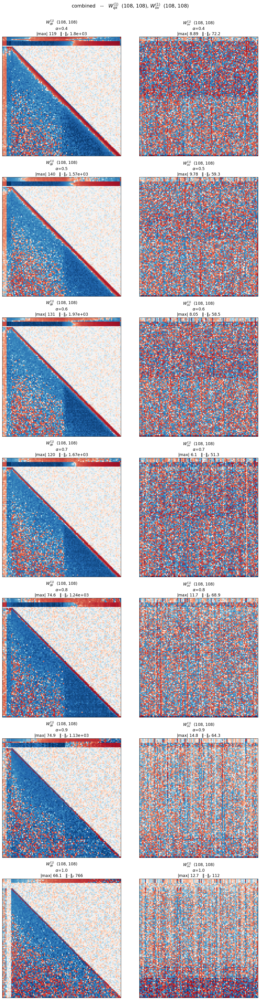

In [13]:
grid(['W_qk1', 'W_ov1'], 'combined',
     ['$W_{qk}^{(1)}$  (108, 108)', '$W_{ov}^{(1)}$  (108, 108)'])


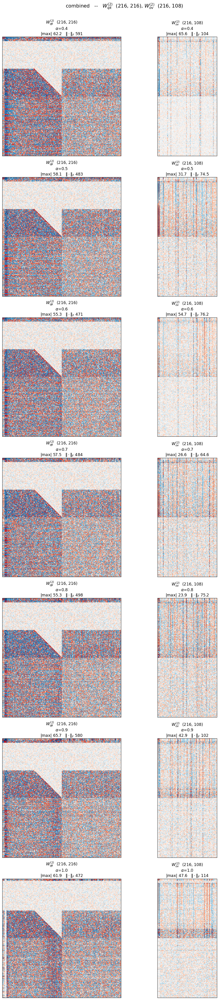

In [14]:
grid(['W_qk2', 'W_ov2'], 'combined',
     ['$W_{qk}^{(2)}$  (216, 216)', '$W_{ov}^{(2)}$  (216, 108)'])


## 4. `separate` — the four matrices as learned, then their products

### 4a. Individually

These carry the within-head rotation gauge: $W_q \to W_qM,\ W_k \to W_kM^{-\top}$ and
$W_v \to W_vB,\ W_o \to B^{-1}W_o$ change nothing. Structure visible here is **not** a property
of the model. They are plotted because you asked to see them, and because the contrast with
§4b is the point.


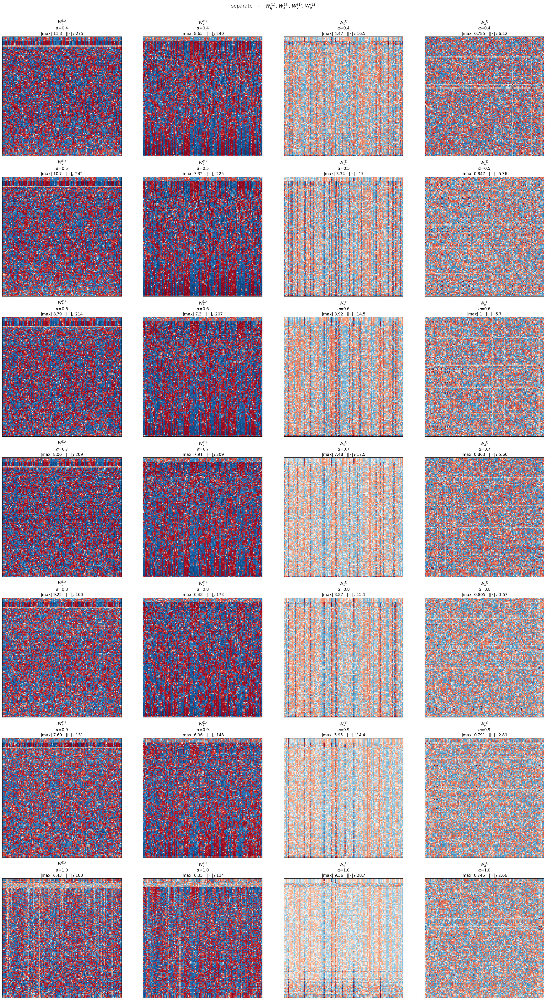

In [15]:
grid(['W_q1', 'W_k1', 'W_v1', 'W_o1'], 'separate',
     ['$W_q^{(1)}$', '$W_k^{(1)}$', '$W_v^{(1)}$', '$W_o^{(1)}$'])


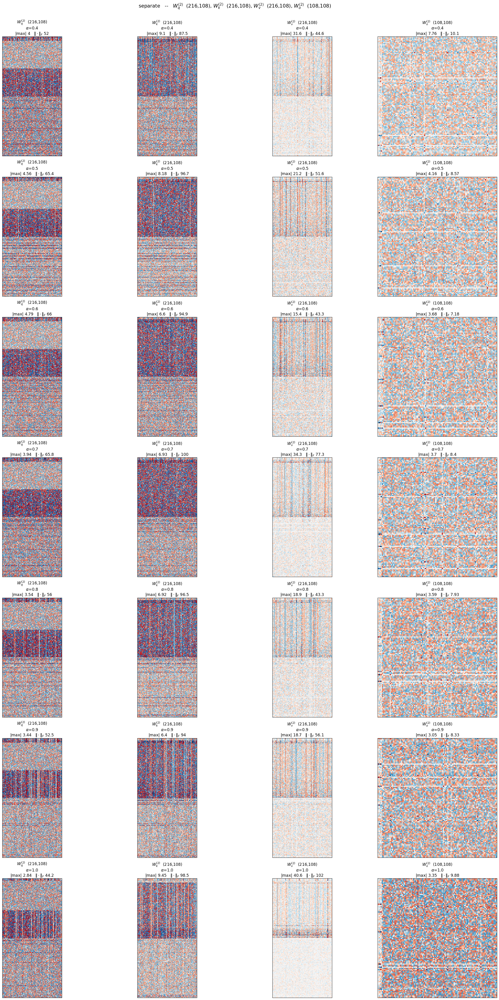

In [16]:
grid(['W_q2', 'W_k2', 'W_v2', 'W_o2'], 'separate',
     ['$W_q^{(2)}$  (216,108)', '$W_k^{(2)}$  (216,108)',
      '$W_v^{(2)}$  (216,108)', '$W_o^{(2)}$  (108,108)'])


### 4b. After multiplication — $W_{qk}=W_qW_k^\top$, $W_{ov}=W_vW_o$

These are the gauge-invariant circuits, and the objects that should be compared with
`combined` and with the hand construction.


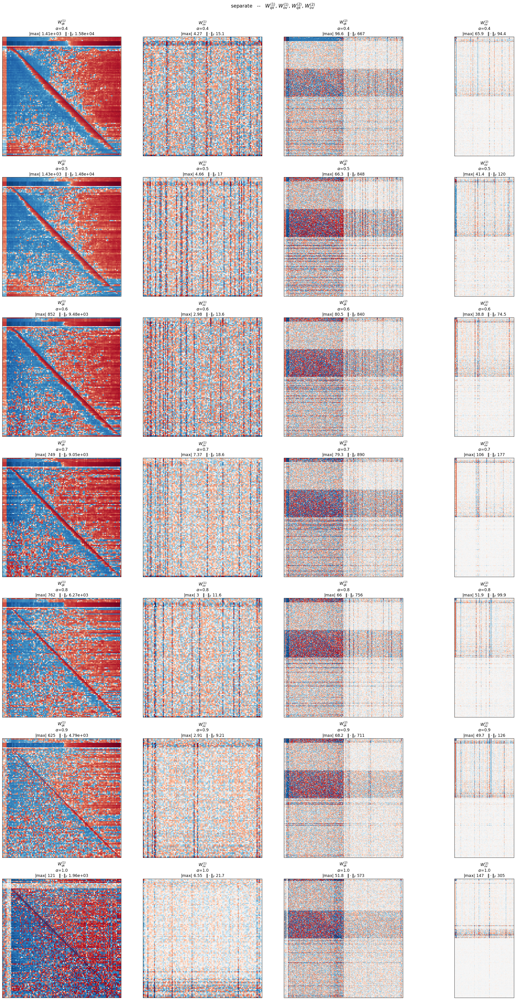

In [17]:
grid(['W_qk1', 'W_ov1', 'W_qk2', 'W_ov2'], 'separate',
     ['$W_{qk}^{(1)}$', '$W_{ov}^{(1)}$', '$W_{qk}^{(2)}$', '$W_{ov}^{(2)}$'])


### 4c. Side by side — does the parametrisation change where GD lands?

Same circuit, two parametrisations, plotted on the same cuts. Remember $W_{qk}$ carries the
softmax row-shift gauge on top, so compare *contrasts within a query row*, not absolute cells.


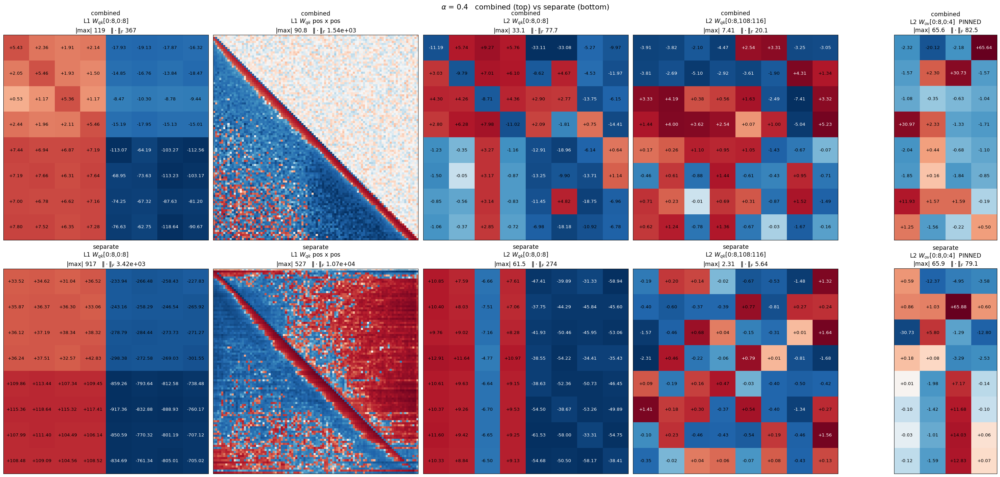

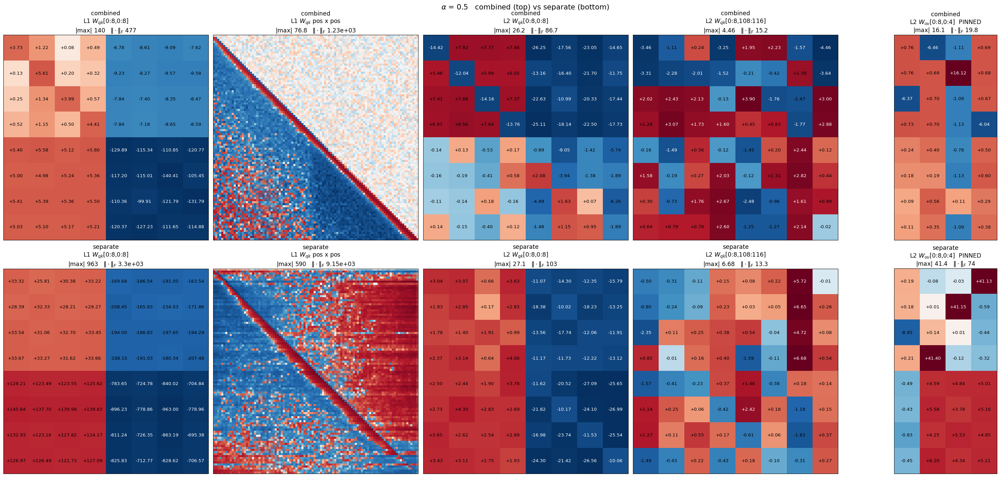

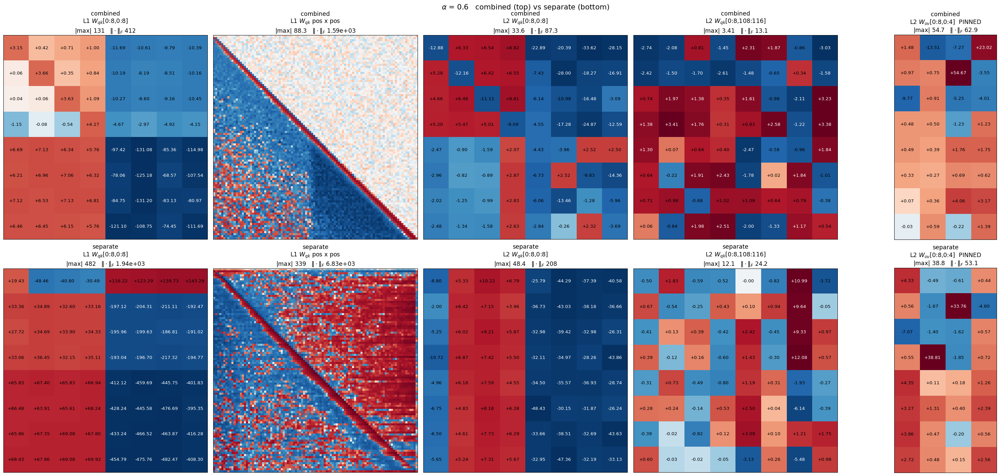

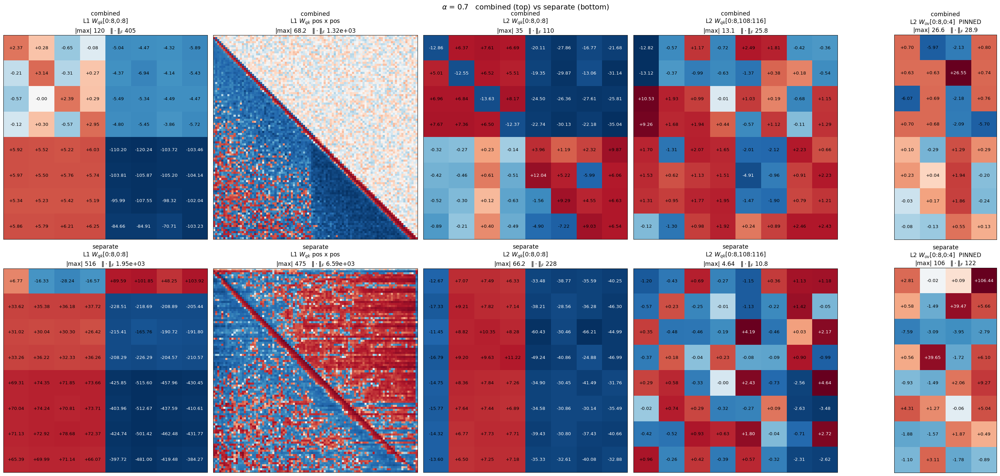

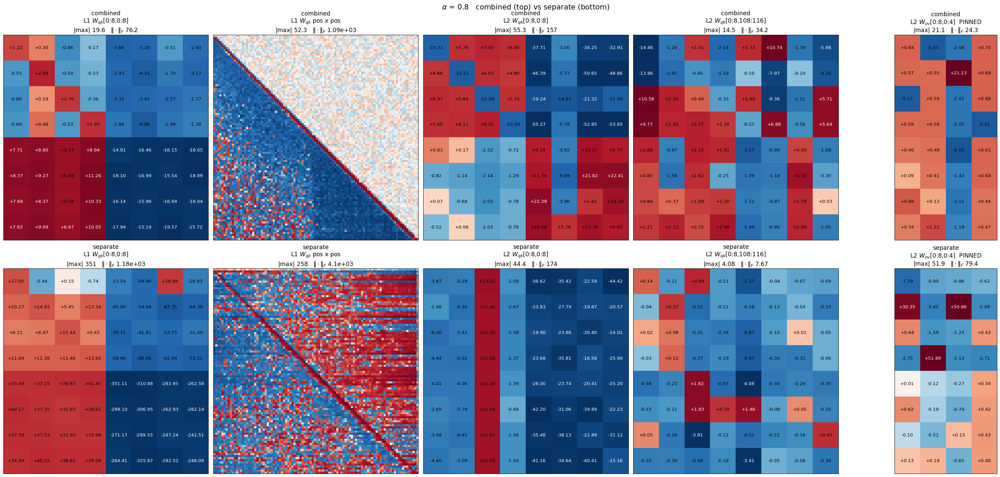

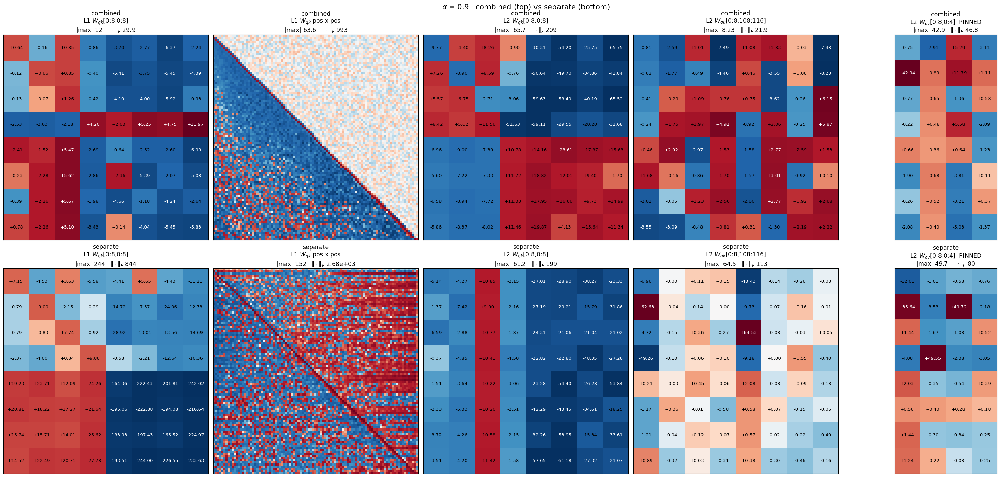

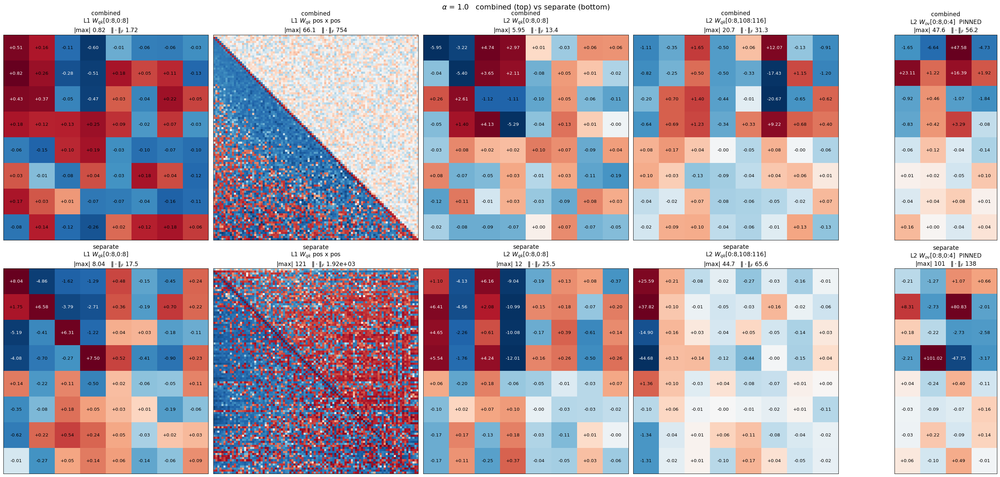

In [18]:
CUTS = [('W_qk1', np.s_[0:V, 0:V],            'L1 $W_{qk}$[0:8,0:8]'),
        ('W_qk1', np.s_[V:D1, V:D1],          'L1 $W_{qk}$ pos x pos'),
        ('W_qk2', np.s_[0:V, 0:V],            'L2 $W_{qk}$[0:8,0:8]'),
        ('W_qk2', np.s_[0:V, D1:D1 + V],      'L2 $W_{qk}$[0:8,108:116]'),
        ('W_ov2', np.s_[0:V, 0:Vs],           'L2 $W_{ov}$[0:8,0:4]  PINNED')]
for t in THRS:
    fig, ax = plt.subplots(2, len(CUTS),
                           figsize=(FIGSCALE * len(CUTS), FIGSCALE * 2.3))
    for j, (k, sl, ttl) in enumerate(CUTS):
        for i, a in enumerate(ARCHS):
            heat(ax[i, j], MAT[(a, t)][k][sl], f'{a}\n{ttl}',
                 annot=(MAT[(a, t)][k][sl].size <= 256))
    fig.suptitle(f'$\\alpha$ = {t}   combined (top) vs separate (bottom)',
                 fontsize=max(13, int(2.6 * FIGSCALE)))
    plt.tight_layout(); plt.show()


## 5. The unembedding, and $W_{ov}^{(2)}$ composed with it

This is the gauge question. $W_{ov}^{(2)}$ alone and $W_u$ alone can each be rotated into
anything by $W_{ov}^{(2)} \to W_{ov}^{(2)}A$, $W_u[:,216{:}324] \to W_u[:,216{:}324]A^{-1}$.
Three things are plotted per threshold:

1. **$W_u$** — the full $(8, 324)$ unembedding. Columns `216:324` are the part that reads
   layer 2; columns `0:216` read the raw stream and layer 1.
2. **$W_{ov}^{(2)}[:, 0{:}4]$, token rows** — the four **gauge-pinned** columns. The frozen log
   sits on exactly these, so no $A$ can move them. The construction says this should be $I_4$
   on the signal token rows: attending token $v$ adds 1 to count slot $v$.
3. **$C = W_{ov}^{(2)}W_u[:,216{:}324]^\top$**, and its token block $C[0{:}8,:]$ — "attending a
   position holding token $v$ moves logit $w$ by this much". Gauge-invariant, and the thing to
   read if the individual matrices look like noise.


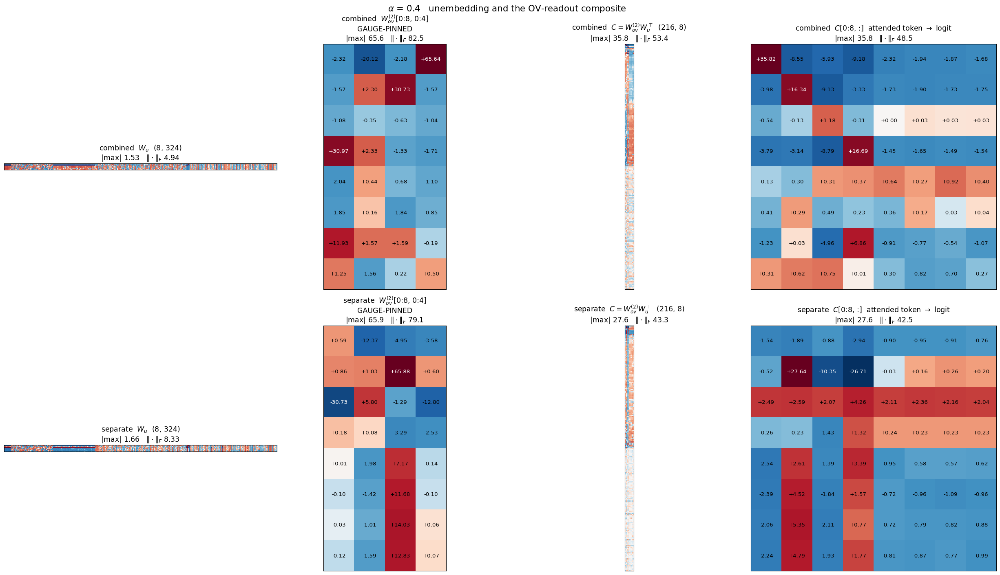

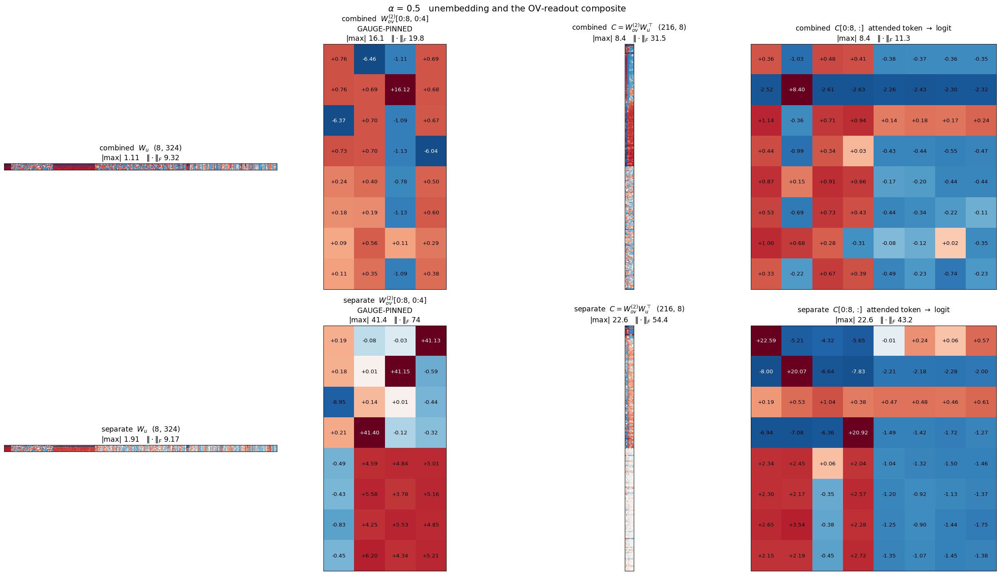

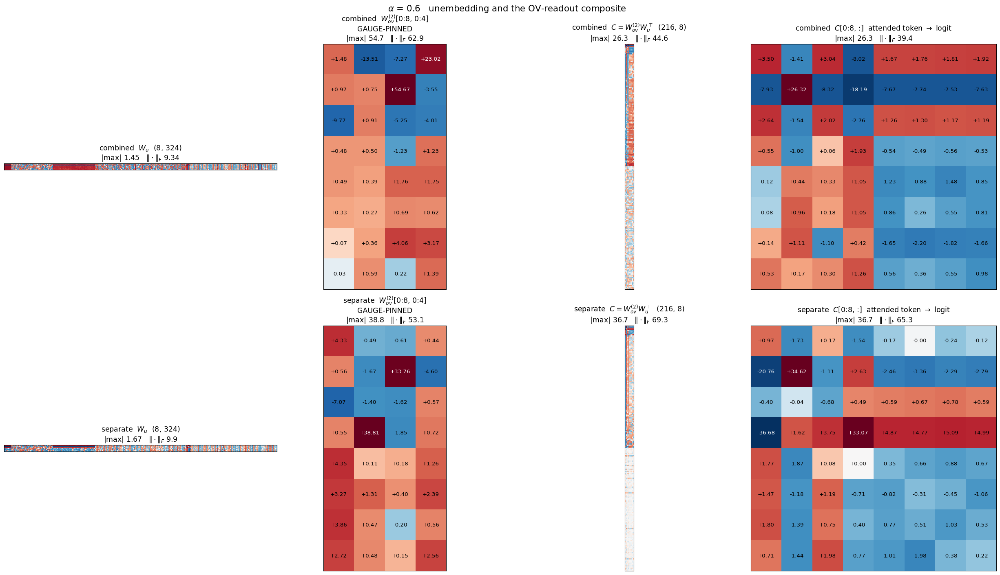

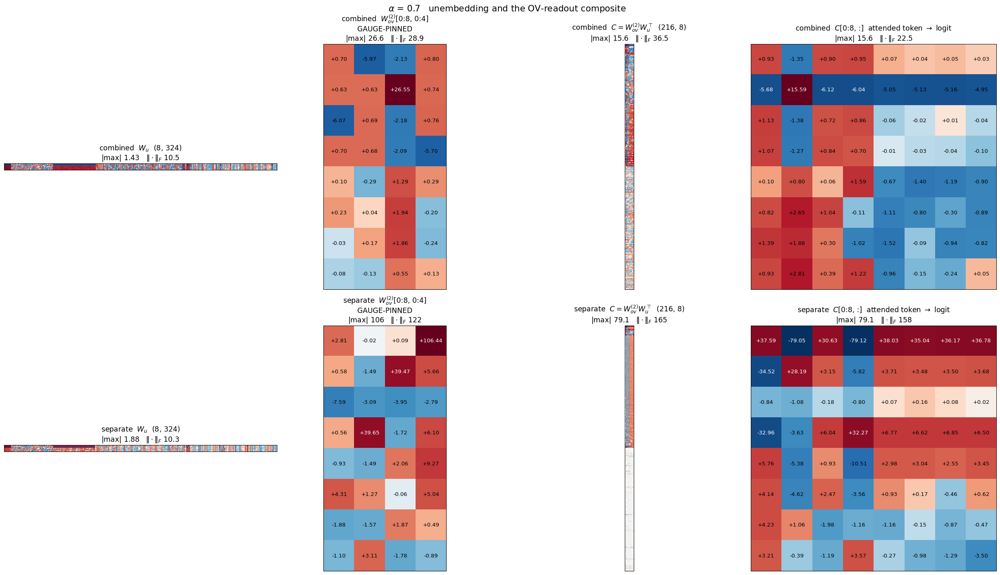

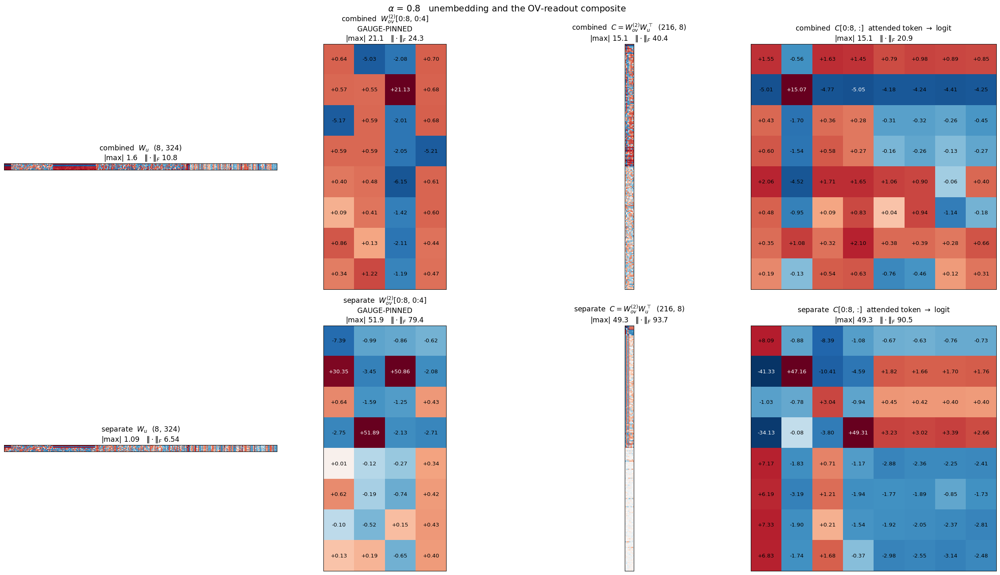

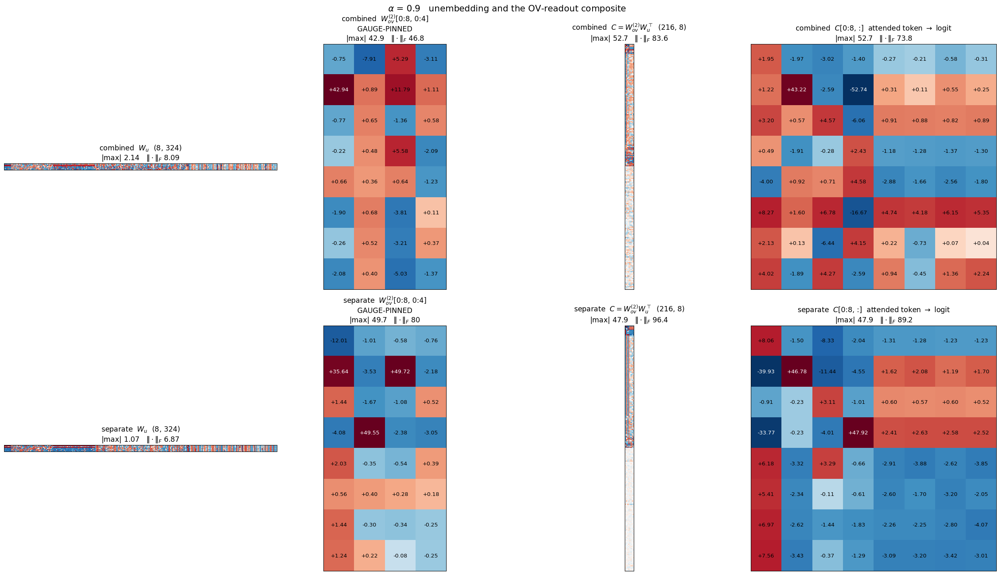

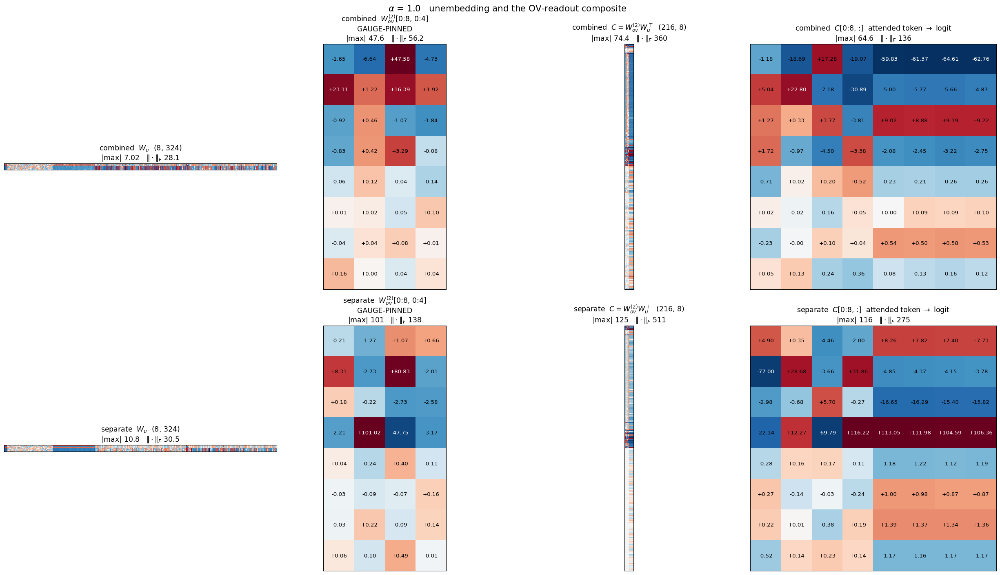

In [19]:
for t in THRS:
    fig, ax = plt.subplots(2, 4, figsize=(FIGSCALE * 4, FIGSCALE * 2.3))
    for i, a in enumerate(ARCHS):
        m = MAT[(a, t)]
        heat(ax[i, 0], m['W_u'], f'{a}  $W_u$  (8, 324)')
        heat(ax[i, 1], m['W_ov2'][0:V, 0:Vs],
             f'{a}  $W_{{ov}}^{{(2)}}$[0:8, 0:4]\nGAUGE-PINNED', annot=True)
        heat(ax[i, 2], m['C'], f'{a}  $C = W_{{ov}}^{{(2)}}W_u^\\top$  (216, 8)')
        heat(ax[i, 3], m['C'][0:V, :],
             f'{a}  $C$[0:8, :]  attended token $\\to$ logit', annot=True)
    fig.suptitle(f'$\\alpha$ = {t}   unembedding and the OV-readout composite',
                 fontsize=max(13, int(2.6 * FIGSCALE)))
    plt.tight_layout(); plt.show()


## 6. Is it interpretable, or has the gauge eaten it?

Three numbers per checkpoint.

* **pinned-block score** — cosine between $W_{ov}^{(2)}[0{:}4,0{:}4]$ and $I_4$. The frozen log
  pins this, so a *low* score here is a real finding, not a gauge artefact.
* **how much of $W_{ov}^{(2)}$ lives in the pinned columns** — $\|[:,0{:}4]\|_F^2$ as a share of
  the whole. The other 104 columns are gauge-free; if most of the energy is there, the raw
  matrix will look like noise however you plot it.
* **composite diagonal dominance** — on $C[0{:}4,0{:}4]$, mean diagonal minus mean
  off-diagonal, in logit units. Positive means "attending token $v$ raises logit $v$ above the
  others", which is the induction head doing its job, and it is gauge-invariant.


In [20]:
def cos(A, B):
    a, b = np.asarray(A).ravel(), np.asarray(B).ravel()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


hdr = (f'{"alpha":>6}{"arch":>10}{"pinned vs I_4":>15}{"energy in cols 0:4":>21}'
       f'{"C diag - offdiag":>19}{"best_test":>12}')
print(hdr); print('-' * len(hdr))
for t in THRS:
    for a in ARCHS:
        m = MAT[(a, t)]
        P = m['W_ov2'][0:Vs, 0:Vs]
        share = (np.linalg.norm(m['W_ov2'][:, 0:Vs]) ** 2
                 / np.linalg.norm(m['W_ov2']) ** 2)
        Cs = m['C'][0:Vs, 0:Vs]
        dd = float(np.mean(np.diag(Cs)) - np.mean(Cs[~np.eye(Vs, dtype=bool)]))
        print(f'{t:>6}{a:>10}{cos(P, np.eye(Vs)):>+15.4f}{100 * share:>20.2f}%'
              f'{dd:>+19.4f}{MET[(a, t)]["best_test"]:>12.5f}')

for line in [
    '',
    'Reading it',
    '----------',
    '* The PINNED column is the only one of the three that says anything about W_ov2 as a',
    '  matrix. It cannot be improved or destroyed by a change of basis, because the frozen',
    '  elementwise log sits on those four coordinates.',
    '* The ENERGY column says how much of W_ov2 you are even entitled to interpret. Whatever',
    '  sits in columns 4:108 is defined only up to an invertible 104x104 transform, so a raw',
    '  plot of those columns is a picture of the basis GD happened to land in.',
    '* The COMPOSITE column is gauge-free and is the honest summary: positive means attending',
    '  a position holding token v pushes logit v up relative to the rest.',
]:
    print(line)


 alpha      arch  pinned vs I_4   energy in cols 0:4   C diag - offdiag   best_test
-----------------------------------------------------------------------------------
   0.4  combined        -0.0145               75.10%           +22.2394     1.86980
   0.4  separate        -0.0146               71.77%           +10.3628     1.81232
   0.5  combined        -0.1444               40.40%            +2.9073     1.80793
   0.5  separate        -0.0008               76.26%           +20.8986     1.76164
   0.6  combined        -0.0143               78.67%           +12.0154     1.70410
   0.6  separate        +0.0168               54.68%           +21.4619     1.66362
   0.7  combined        -0.1138               47.99%            +5.8263     1.55397
   0.7  separate        +0.0143               51.98%           +40.9666     1.52902
   0.8  combined        -0.1295               31.37%            +5.4508     1.36750
   0.8  separate        -0.0932               66.98%           +35.8558     

---

# 7. The frozen-unembedding run

Checkpoints from **`train_equiprobable_frozen_unembed.py`** — the same model and data, `combined`
only, with `fc_out` pinned to the construction's selector and dropped from the optimizer. The
only trained parameters are the four attention matrices (93,312 numbers).

**Why the matrices below mean something that §3–§5's did not.** With `fc_out` trained there is an
exact gauge $W_{ov}^{(2)} \to W_{ov}^{(2)}A$, $W_u[:,216{:}324] \to W_u[:,216{:}324]A^{-1}$, so
$W_{ov}^{(2)}$ could sit in any basis and §6 measured that it did — cosine $\approx 0$ against
$I_4$ at every threshold. Here $W_u$ is frozen to

$$W_u[v,\,216+v] = 1 \;\; (v<4), \qquad b_u = [0,0,0,0,\beta,\beta,\beta,\beta]$$

with 4 nonzero weights out of 2,592. There is no $A$ left. So $W_{ov}^{(2)}[0{:}8,\,0{:}4]$ is now
**directly** the count extractor, and the construction's prediction — $I_4$ on the signal token
rows, zero on the noise rows — is a claim that can be read straight off the plot.

Note also that the composite $C = W_{ov}^{(2)}W_u[:,216{:}324]^\top$ is no longer a separate
object: since $W_u$ is the selector, $C$ is just $W_{ov}^{(2)}[:,0{:}4]$ padded with zeros. So
there is one matrix to look at, not two.

Some thresholds may still be training — this section uses whatever is on disk.


In [21]:
FROZEN_PREFIX = 'equi-frozenU'
FZ_THR = None          # None -> the first threshold that has finished; or set e.g. 0.6

fz_dirs = sorted(d for d in glob.glob(os.path.join('runs', FROZEN_PREFIX + '_*'))
                 if os.path.isdir(d))      # the _summary.json also matches the glob
FZ_RUN = fz_dirs[-1] if fz_dirs else None
FZ = {}
if FZ_RUN:
    for q in sorted(glob.glob(os.path.join(FZ_RUN, 'model_combined_seed*_x_*.pth'))):
        t = float(q.split('_x_')[-1][:-4])
        sd = torch.load(q, map_location='cpu', weights_only=True)
        m_ = {}
        for L in (1, 2):
            m_[f'W_qk{L}'] = sd[f'layer{L}.W_qk'].numpy().astype(np.float64)
            m_[f'W_ov{L}'] = sd[f'layer{L}.W_ov'].numpy().astype(np.float64)
        m_['W_u'] = sd['fc_out.weight'].numpy().astype(np.float64)
        m_['b_u'] = sd['fc_out.bias'].numpy().astype(np.float64)
        FZ[t] = m_

print(f'frozen-unembed run : {FZ_RUN}')
if not FZ:
    print('\n  no finished checkpoints yet -- the first threshold is still training.')
    print('  Re-run this cell (and the ones below) once a model_combined_seed0_x_*.pth appears.')
else:
    FZ_THRS = sorted(FZ)
    FZ_T = FZ_THR if FZ_THR in FZ else FZ_THRS[0]
    print(f'available thresholds : {FZ_THRS}      plotting alpha = {FZ_T}')
    # confirm the unembedding really is the frozen selector
    Wu = FZ[FZ_T]['W_u']; bu = FZ[FZ_T]['b_u']
    nzc = [tuple(int(i) for i in idx) for idx in np.argwhere(Wu != 0)]
    print(f'\nfc_out check: {len(nzc)} nonzero weights at {nzc}')
    print(f'              b_u = {[round(float(v), 5) for v in bu]}')
    print(f'              -> frozen selector intact, beta = {bu[Vs]:+.6f}')
    # loss, frozen vs trained unembedding
    fzm = json.load(open(os.path.join(FZ_RUN, f'metrics_combined_seed0_x_{FZ_T}.json')))
    cfg = fzm['config']
    print(f'\nrun settings : lr={cfg["lr"]}  batch={cfg["batch_size"]}  '
          f'epochs={cfg["epochs"]}  epochs_run={fzm["epochs_run"]}')
    print(f'\n{"":>24}{"best_train":>12}{"best_test":>12}')
    print(f'{"frozen unembedding":>24}{fzm["best_train"]:>12.5f}{fzm["best_test"]:>12.5f}')
    if (("combined", FZ_T)) in MET:
        tm = MET[('combined', FZ_T)]
        print(f'{"trained unembedding":>24}{tm["best_train"]:>12.5f}{tm["best_test"]:>12.5f}')
        print(f'{"cost of freezing":>24}{fzm["best_train"]-tm["best_train"]:>+12.5f}'
              f'{fzm["best_test"]-tm["best_test"]:>+12.5f}')
        print(f'\n(note: the two runs use different lr/epochs -- {cfg["lr"]}/{cfg["epochs"]} vs '
              f'{MET[("combined", FZ_T)]["config"]["lr"]}/'
              f'{MET[("combined", FZ_T)]["config"]["epochs"]} -- so this gap is not a clean\n'
              f' one-variable comparison. It mixes the freezing with the optimiser change.)')


frozen-unembed run : runs/equi-frozenU_opt-adam_lr-0.05_b-256_init-normal_ep-500
available thresholds : [0.6]      plotting alpha = 0.6

fc_out check: 4 nonzero weights at [(0, 216), (1, 217), (2, 218), (3, 219)]
              b_u = [0.0, 0.0, 0.0, 0.0, -1.75254, -1.75254, -1.75254, -1.75254]
              -> frozen selector intact, beta = -1.752539

run settings : lr=0.05  batch=256  epochs=500  epochs_run=500

                          best_train   best_test
      frozen unembedding     1.69928     1.70409
     trained unembedding     1.66263     1.70410
        cost of freezing    +0.03665    -0.00001

(note: the two runs use different lr/epochs -- 0.05/500 vs 0.003/2000 -- so this gap is not a clean
 one-variable comparison. It mixes the freezing with the optimiser change.)


## 7a. The four trained matrices

Everything else in the model is frozen, so this is the entire learned circuit.


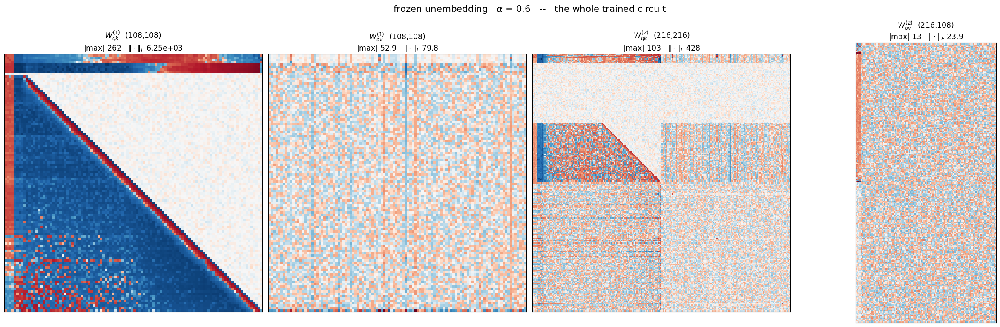

In [22]:
if FZ:
    keys = [('W_qk1', '$W_{qk}^{(1)}$  (108,108)'), ('W_ov1', '$W_{ov}^{(1)}$  (108,108)'),
            ('W_qk2', '$W_{qk}^{(2)}$  (216,216)'), ('W_ov2', '$W_{ov}^{(2)}$  (216,108)')]
    fig, ax = plt.subplots(1, 4, figsize=(FIGSCALE * 4, FIGSCALE * 1.25))
    for j, (k, lab) in enumerate(keys):
        heat(ax[j], FZ[FZ_T][k], lab)
    fig.suptitle(f'frozen unembedding   $\\alpha$ = {FZ_T}   --   the whole trained circuit',
                 fontsize=max(14, int(2.6 * FIGSCALE)))
    plt.tight_layout(); plt.show()


## 7b. $W_{ov}^{(2)}$'s count block — the one the gauge used to hide

Left: the $8\times4$ token block, annotated. The construction says $I_4$ on rows 0:4 (attending
token $v$ adds 1 to count slot $v$) and **zero on rows 4:8** (a noise token must contribute
nothing, or it pollutes the count).

Right: the same block from the *trained*-unembedding run at the same $\alpha$, for contrast —
that one is only defined up to $A$, so its structure is not expected to mean anything.

Below: the full $(216,4)$ columns, to check nothing large is hiding in the position or
layer-1-output rows.


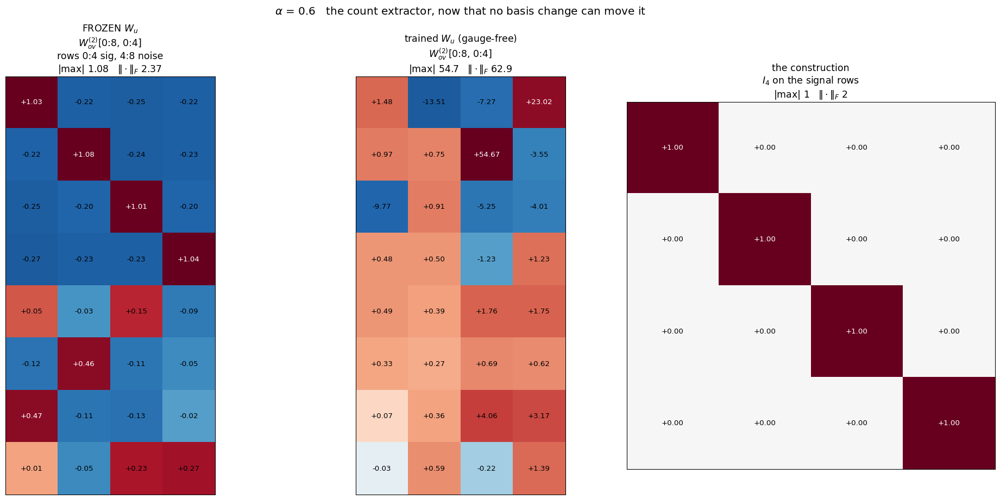

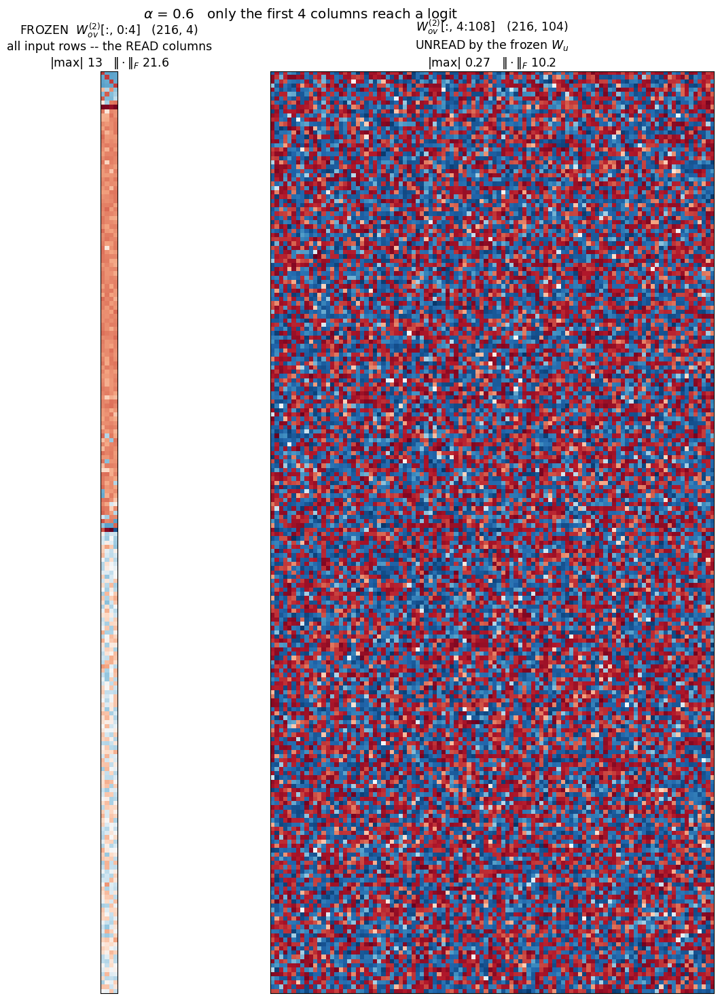

In [25]:
if FZ:
    fig, ax = plt.subplots(1, 3, figsize=(FIGSCALE * 3.2, FIGSCALE * 1.5))
    heat(ax[0], FZ[FZ_T]['W_ov2'][0:V, 0:Vs],
         f'FROZEN $W_u$\n$W_{{ov}}^{{(2)}}$[0:8, 0:4]\nrows 0:4 sig, 4:8 noise', annot=True)
    if ('combined', FZ_T) in MAT:
        heat(ax[1], MAT[('combined', FZ_T)]['W_ov2'][0:V, 0:Vs],
             f'trained $W_u$ (gauge-free)\n$W_{{ov}}^{{(2)}}$[0:8, 0:4]', annot=True)
    else:
        ax[1].axis('off')
    heat(ax[2], np.eye(Vs, dtype=float),
         'the construction\n$I_4$ on the signal rows', annot=True)
    fig.suptitle(f'$\\alpha$ = {FZ_T}   the count extractor, now that no basis change can move it',
                 fontsize=max(13, int(2.4 * FIGSCALE)))
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(1, 2, figsize=(FIGSCALE * 2.2, FIGSCALE * 2.4))
    heat(ax[0], FZ[FZ_T]['W_ov2'][:, 0:Vs],
         'FROZEN  $W_{ov}^{(2)}$[:, 0:4]   (216, 4)\nall input rows -- the READ columns')
    heat(ax[1], FZ[FZ_T]['W_ov2'][:, Vs:],
         '$W_{ov}^{(2)}$[:, 4:108]   (216, 104)\nUNREAD by the frozen $W_u$')
    fig.suptitle(f'$\\alpha$ = {FZ_T}   only the first 4 columns reach a logit',
                 fontsize=max(13, int(2.4 * FIGSCALE)))
    plt.tight_layout(); plt.show()


## 7c. Did it find the construction?

`pinned vs I_4` is now a real measurement, not a gauge artefact. `noise leakage` is the extra
check the trained run could not make: $\|W_{ov}^{(2)}[4{:}8,\,0{:}4]\|_F$ relative to the signal
rows — the construction wants it at zero, because a noise token contributing to a count slot is
exactly what the layer-2 noise veto exists to prevent.

`energy in read columns` should now be near 100% if GD has understood that columns 4:108 feed
nothing — if it is low, a lot of $W_{ov}^{(2)}$ is being learned into coordinates no logit reads.


In [ ]:
if FZ:
    def cos_(A, B):
        a, b = np.asarray(A).ravel(), np.asarray(B).ravel()
        n = np.linalg.norm(a) * np.linalg.norm(b)
        return float(a @ b / n) if n else 0.0

    hdr = (f'{"alpha":>6}{"unembed":>12}{"pinned vs I_4":>15}{"noise leakage":>15}'
           f'{"energy in read cols":>21}{"best_test":>12}')
    print(hdr); print('-' * len(hdr))
    for t in sorted(FZ):
        W2 = FZ[t]['W_ov2']
        sig_n = np.linalg.norm(W2[0:Vs, 0:Vs])
        leak = np.linalg.norm(W2[Vs:V, 0:Vs]) / sig_n if sig_n else float('nan')
        share = np.linalg.norm(W2[:, 0:Vs]) ** 2 / np.linalg.norm(W2) ** 2
        bt = json.load(open(os.path.join(FZ_RUN,
                       f'metrics_combined_seed0_x_{t}.json')))['best_test']
        print(f'{t:>6}{"FROZEN":>12}{cos_(W2[0:Vs, 0:Vs], np.eye(Vs)):>+15.4f}'
              f'{leak:>15.4f}{100 * share:>20.2f}%{bt:>12.5f}')
        if ('combined', t) in MAT:
            W2b = MAT[('combined', t)]['W_ov2']
            sn = np.linalg.norm(W2b[0:Vs, 0:Vs])
            lk = np.linalg.norm(W2b[Vs:V, 0:Vs]) / sn if sn else float('nan')
            sh = np.linalg.norm(W2b[:, 0:Vs]) ** 2 / np.linalg.norm(W2b) ** 2
            print(f'{"":>6}{"trained":>12}{cos_(W2b[0:Vs, 0:Vs], np.eye(Vs)):>+15.4f}'
                  f'{lk:>15.4f}{100 * sh:>20.2f}%{MET[("combined", t)]["best_test"]:>12.5f}')

    for line in ['',
        'The trained-unembedding row is shown only as a foil. Its numbers are gauge-dependent',
        'and a cosine near 0 there means "different basis", not "wrong circuit". The FROZEN row',
        'is the one that can be read literally, because the construction selector leaves no A.']:
        print(line)


 alpha     unembed  pinned vs I_4  noise leakage  energy in read cols   best_test
---------------------------------------------------------------------------------
   0.6      FROZEN        +0.9338         0.3625               81.79%     1.70409
           trained        -0.0143         0.0967               78.67%     1.70410

The trained-unembedding row is shown only as a foil. Its numbers are gauge-dependent
and a cosine near 0 there means "different basis", not "wrong circuit". The FROZEN row
is the one that can be read literally, because the construction selector leaves no A.


---

# 8. Why the products — derived from scratch

§7 plots raw blocks of $W_{qk}^{(2)}$ and $W_{ov}^{(1)}$ that look structureless. This section
shows why, and what to plot instead. Every claim is checked in the cell below it.

## 8.1 What layer 2 actually computes

Layer 2's input at position $t$ is the concatenation

$$x^{(2)}_t = [\,\underbrace{x_t}_{108}\;;\;\underbrace{h_t}_{108}\,] \in \mathbb{R}^{216},
\qquad h_t = \sum_s a^{(1)}_{t,s}\bigl(x_s W_{ov}^{(1)}\bigr)$$

with $x_t$ the input embedding (token one-hot $\oplus$ position one-hot) and $h_t$ layer 1's
attention output. Split $W_{qk}^{(2)}$ into four $108\times108$ blocks to match:

$$W_{qk}^{(2)} = \begin{bmatrix} P & Q \\ R & S \end{bmatrix},\qquad
S_{t,u} = \underbrace{x_tPx_u^\top}_{\text{embed}\times\text{embed}}
+ \underbrace{x_tQh_u^\top}_{\textbf{induction}}
+ \underbrace{h_tRx_u^\top}_{\text{cross}}
+ \underbrace{h_tSh_u^\top}_{\textbf{state}}$$

The construction's blocks live in these terms: **A** (noise suppression) is $P[0{:}8,0{:}8]$,
**B** (induction) is the $Q$ term, **C** (state) is the $S$ term.

## 8.2 Substituting what $h$ is — where the products come from

If layer 1 works, $h_u$ is the embedding of $u$'s most recent preceding signal position pushed
through $W_{ov}^{(1)}$, so with $\mathrm{prev}(u)$ that token,
$h_u = W_{ov}^{(1)}[\mathrm{prev}(u),:]$ — a single **row** of $W_{ov}^{(1)}$. Substituting:

$$\textbf{B: }\; x_tQh_u^\top = e_{v_t}Q\,W_{ov}^{(1)}[\mathrm{prev}(u),:]^\top
= \bigl(\underbrace{Q[0{:}8,:]\,W_{ov}^{(1)}[0{:}8,:]^\top}_{M_B}\bigr)_{v_t,\;\mathrm{prev}(u)}$$

$h$ appears **once** (key side only) $\Rightarrow$ $W_{ov}^{(1)}$ appears **once**.

$$\textbf{C: }\; h_tSh_u^\top
= W_{ov}^{(1)}[\mathrm{prev}(t),:]\,S\,W_{ov}^{(1)}[\mathrm{prev}(u),:]^\top
= \bigl(\underbrace{W_{ov}^{(1)}[0{:}8,:]\,S\,W_{ov}^{(1)}[0{:}8,:]^\top}_{M_C}\bigr)_{\mathrm{prev}(t),\,\mathrm{prev}(u)}$$

$h$ appears on **both** sides $\Rightarrow$ $W_{ov}^{(1)}$ appears **twice, one transposed**.
That is the entire reason for the sandwich — it is substitution into a bilinear form, nothing more.

Read the results directly: $M_B[v,u]$ = "I am token $v$; how much do I want a key whose
predecessor was $u$?" (construction wants **diagonal**, $P_1$). $M_C[v,u]$ = "my predecessor was
$v$; how much do I want a key whose predecessor was $u$?" (also **diagonal**, $P_2$).


In [ ]:
import torch.nn.functional as F
import importlib.util as _ilu

# model class + loss straight from the training script, so this can never drift from what ran
_spec = _ilu.spec_from_file_location('_tr', 'train_equiprobable_frozen_unembed.py')
TR = _ilu.module_from_spec(_spec); _spec.loader.exec_module(TR)
SimplifiedTransformerMLP = TR.SimplifiedTransformerMLP
CFG_K = TR.CFG['freeze_hidden_k']


def eval_ce_(model, xb, yb):
    return TR.eval_ce(model, xb, yb, V, torch.device('cpu'))


def blocks(sd_):
    W = sd_['layer2.W_qk']
    return W[:D1, :D1], W[:D1, D1:], W[D1:, :D1], W[D1:, D1:]      # P, Q, R, S


def composites(sd_):
    """The gauge-invariant 8x8 views of the three construction blocks."""
    P, Q, Rb, S = blocks(sd_)
    O = sd_['layer1.W_ov'][0:V, :].numpy().astype(np.float64)
    return {'A': P[0:V, 0:V].numpy().astype(np.float64),
            'B': Q[0:V, :].numpy().astype(np.float64) @ O.T,
            'C': O @ S.numpy().astype(np.float64) @ O.T,
            'cross': O @ Rb[:, 0:V].numpy().astype(np.float64)}


_sd = None
if FZ:
    _sd = torch.load(os.path.join(FZ_RUN, f'model_combined_seed0_x_{FZ_T}.pth'),
                     map_location='cpu', weights_only=True)
    blob = torch.load(os.path.join('dataset', 'test', f'data_x_{FZ_T}.pt'), weights_only=False)
    xb2, yb = blob['x'][:256], blob['y'][:256]
    mdl = SimplifiedTransformerMLP(V, 100, 108, Vs, CFG_K, True, 'combined')
    mdl.load_state_dict(_sd); mdl.eval()

    xb = blob['x'][:8]
    Bn, Tn = xb.shape
    s1 = torch.cat([F.one_hot(xb, V).float(),
                    F.one_hot(torch.arange(Tn), 100).float().unsqueeze(0).expand(Bn, Tn, -1)], -1)
    msk = torch.triu(torch.ones(Tn, Tn) * float('-inf'), diagonal=1)
    sc1 = torch.bmm(s1 @ _sd['layer1.W_qk'], s1.transpose(1, 2)) / (D1 ** 0.5) + msk
    h = torch.bmm(F.softmax(sc1, -1), s1 @ _sd['layer1.W_ov'])
    x2 = torch.cat([s1, h], -1)
    P, Q, Rb, S = blocks(_sd)
    full = torch.bmm(x2 @ _sd['layer2.W_qk'], x2.transpose(1, 2))
    four = (torch.bmm(s1 @ P, s1.transpose(1, 2)) + torch.bmm(s1 @ Q, h.transpose(1, 2))
            + torch.bmm(h @ Rb, s1.transpose(1, 2)) + torch.bmm(h @ S, h.transpose(1, 2)))
    print(f'check 1  score == xPx^T + xQh^T + hRx^T + hSh^T : '
          f'max|diff| = {float((full - four).abs().max()):.2e}')
else:
    print('no frozen-unembed checkpoint yet -- section 8 needs one.')


## 8.3 The gauge — why the raw blocks are structureless

$h$ enters the model **only** through those bilinear terms and through $W_{ov}^{(2)}$'s rows
`108:216`. So for any invertible $A$,

$$W_{ov}^{(1)} \to W_{ov}^{(1)}A \;\Rightarrow\; h \to hA, \qquad
Q \to QA^{-\top},\; R \to A^{-1}R,\; S \to A^{-1}SA^{-\top},\;
W_{ov}^{(2)}[108{:},:] \to A^{-1}W_{ov}^{(2)}[108{:},:]$$

leaves every score and logit bit-for-bit identical. And $A$ cancels in the composites:

$$M_B' = (QA^{-\top})(W_{ov}^{(1)}A)^\top = QA^{-\top}A^\top W_{ov}^{(1)\top} = M_B,\qquad
M_C' = (W_{ov}^{(1)}A)(A^{-1}SA^{-\top})(W_{ov}^{(1)}A)^\top = M_C$$

**That is the answer to "why multiply them": the product is what survives a change of basis, and
the factors separately are notation.**


In [ ]:
if _sd is not None:
    ce_before = eval_ce_(mdl, xb2, yb); M0 = composites(_sd)
    gen = torch.Generator().manual_seed(0)
    A = torch.randn(108, 108, generator=gen) / 108 ** 0.5 + torch.eye(108)
    Bm = torch.block_diag(torch.eye(D1), A); Bi = torch.linalg.inv(Bm)
    sd2 = {k: v.clone() for k, v in _sd.items()}
    sd2['layer1.W_ov'] = _sd['layer1.W_ov'] @ A
    sd2['layer2.W_qk'] = Bi @ _sd['layer2.W_qk'] @ Bi.T
    sd2['layer2.W_ov'] = Bi @ _sd['layer2.W_ov']
    mdl.load_state_dict(sd2); ce_after = eval_ce_(mdl, xb2, yb); M1 = composites(sd2)
    print('check 2  random basis change A on layer 1 output')
    print(f'         CE {ce_before:.8f} -> {ce_after:.8f}   delta {ce_after - ce_before:+.2e}')
    print(f'         W_ov1 moved by '
          f'{float((sd2["layer1.W_ov"] - _sd["layer1.W_ov"]).abs().max()):.4g}, '
          f'W_qk2 by {float((sd2["layer2.W_qk"] - _sd["layer2.W_qk"]).abs().max()):.4g}')
    for k in ('A', 'B', 'C'):
        print(f'         composite {k}: max|change| = {np.abs(M0[k] - M1[k]).max():.2e}')
    print('         -> raw factors move enormously, composites do not move.')
    mdl.load_state_dict(_sd)


## 8.4 Where gauge freedom is still left

"Gauge" = a transformation that provably cannot change any output. Not the same as "unused".

| # | freedom | acts on | still there? |
|---|---|---|---|
| 1 | $GL(108)$ on layer 1's output, $A$ | $W_{ov}^{(1)}$; $Q,R,S$ of $W_{qk}^{(2)}$; $W_{ov}^{(2)}[108{:}216,:]$ | **YES** — the big one |
| 2 | softmax row shift across a *complete* key group | both $W_{qk}$ | **YES** |
| 3 | OV/readout $W_{ov}^{(2)}\!\to\!W_{ov}^{(2)}A$, $W_u\!\to\!W_uA^{-1}$ | $W_{ov}^{(2)}[:,0{:}4]$ | **GONE** — freezing $W_u$ killed it |
| 4 | $W_{ov}^{(2)}[:,4{:}108]$ | writes coords `220:324`, which frozen $W_u$ never reads | **DEAD** — not gauge, just unused |

Freedom 1 is why $W_{ov}^{(1)}$ and the B/C blocks look like noise, and it is **not removable by
training** — no gradient direction prefers one basis. The only fix is to freeze $W_{ov}^{(1)}$ to
$I$, as was done for $W_u$. That is the natural next ablation.


In [39]:
if _sd is not None:
    ce0 = eval_ce_(mdl, xb2, yb)
    with torch.no_grad():
        mdl.layer2.W_ov[:, Vs:] = 0.0
    print(f'check 3  zero W_ov2[:, 4:108] : CE {ce0:.8f} -> {eval_ce_(mdl, xb2, yb):.8f}'
          f'   -> DEAD (freedom 4)')
    mdl.load_state_dict(_sd)
    with torch.no_grad():
        c = torch.randn(D1, 1) * 50
        mdl.layer1.W_qk[:, :V] += c
        mdl.layer1.W_qk[:, V:D1] += c * 0.3
    print(f'check 4  per-query constant across complete key groups of W_qk1 : '
          f'CE {ce0:.8f} -> {eval_ce_(mdl, xb2, yb):.8f}   -> GAUGE (freedom 2)')
    mdl.load_state_dict(_sd)


check 3  zero W_ov2[:, 4:108] : CE 1.70594971 -> 1.70594971   -> DEAD (freedom 4)
check 4  per-query constant across complete key groups of W_qk1 : CE 1.70594971 -> 1.70594986   -> GAUGE (freedom 2)


## 8.5 The composites, plotted

$A$ is pinned and readable as-is. $B$ and $C$ are the $8\times8$ views derived in §8.2 — the only
form in which the induction and state circuits are visible.


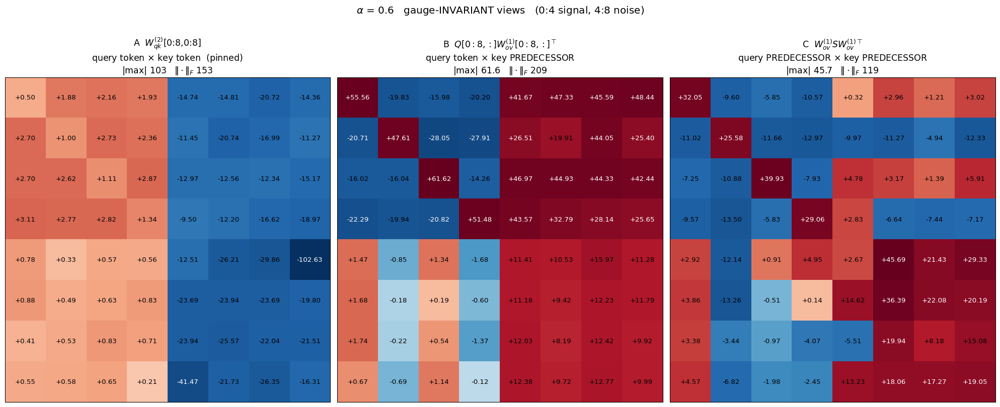

block      signal diag   signal offdiag        DIFF   wants
A                 0.98             2.55       -1.57   no constraint
B                54.07           -20.17      +74.24   diagonal (P1)
C                31.65            -9.72      +41.37   diagonal (P2)


In [40]:
if _sd is not None:
    M = composites(_sd)
    panels = [('A', 'A  $W_{qk}^{(2)}$[0:8,0:8]\nquery token $\\times$ key token  (pinned)'),
              ('B', 'B  $Q[0{:}8,:]W_{ov}^{(1)}[0{:}8,:]^\\top$\n'
                    'query token $\\times$ key PREDECESSOR'),
              ('C', 'C  $W_{ov}^{(1)}SW_{ov}^{(1)\\top}$\n'
                    'query PREDECESSOR $\\times$ key PREDECESSOR')]
    fig, ax = plt.subplots(1, 3, figsize=(FIGSCALE * 3.2, FIGSCALE * 1.5))
    for j, (k, lab) in enumerate(panels):
        heat(ax[j], M[k], lab, annot=True)
    fig.suptitle(f'$\\alpha$ = {FZ_T}   gauge-INVARIANT views   (0:4 signal, 4:8 noise)',
                 fontsize=max(13, int(2.4 * FIGSCALE)))
    plt.tight_layout(); plt.show()

    print(f'{"block":8}{"signal diag":>14}{"signal offdiag":>17}{"DIFF":>12}   wants')
    for k, want in (('A', 'no constraint'), ('B', 'diagonal (P1)'), ('C', 'diagonal (P2)')):
        s_ = M[k][:Vs, :Vs]
        d, o = np.mean(np.diag(s_)), np.mean(s_[~np.eye(Vs, dtype=bool)])
        print(f'{k:8}{d:>14.2f}{o:>17.2f}{d - o:>+12.2f}   {want}')


## 8.6 A gauge-invariant view of $W_{ov}^{(1)}$ — and why it has to be indirect

Strictly, **$W_{ov}^{(1)}$ on its own has no gauge-invariant entries.** Under
$W_{ov}^{(1)} \to W_{ov}^{(1)}A$ with $A$ any invertible $108\times108$, the rows are mapped
$r_i \mapsto r_iA$, so the only things that survive are:

* its **rank**, and
* the **linear dependencies among its rows** (if $\sum_i c_ir_i = 0$ then
  $\sum_i c_i r_iA = 0$ too).

Even the Gram matrix $OO^\top$ is *not* invariant, since $(OA)(OA)^\top = OAA^\top O^\top$.
So "plot a gauge-fixed $W_{ov}^{(1)}$" is not a well-posed request in the way "plot a gauge-fixed
$W_{qk}$" was — there is no canonical representative without *choosing* one.

**What is well-posed:** the rank tells you the only thing that matters functionally. Layer 1 must
map the 8 possible predecessor tokens to 8 *distinguishable* directions, or layer 2 cannot tell
them apart. Rank 8 means it does; rank $r<8$ means $8-r$ tokens have been collapsed and the
induction head is structurally unable to separate them.

**And then a useful convention exists.** If the rank is 8, pick the specific $A$ that sends
$W_{ov}^{(1)}$'s token rows to the identity:

$$A = \bigl[\;O^{+}\;\big|\;N\;\bigr], \qquad O = W_{ov}^{(1)}[0{:}8,:], \qquad
O A = [\,I_8 \;|\; 0\,]$$

with $O^{+}$ the pseudo-inverse ($OO^{+} = I_8$) and $N$ a basis of $O$'s null space (so
$ON = 0$ and $A$ is invertible). This is the **construction's own gauge** — it is exactly what
$W_{ov}^{(1)} = I_8$ means in the hand-built circuit.

After the fix, all the structure has moved into the blocks that read $h$, and they become
directly readable. In fact the raw blocks then *equal* the composites of §8.2:

$$Q'[0{:}8,0{:}8] = M_B, \qquad S'[0{:}8,0{:}8] = M_C$$

which is the cleanest statement of what §8.2 was doing: the composite *is* the raw block, once
you stand in the basis where $W_{ov}^{(1)}$ is the identity.


THE ONLY GAUGE-INVARIANT FACTS ABOUT W_ov1 ALONE
  singular values : [14.5184  3.7992  3.445   3.0719  2.5945  2.4286  2.3339  1.265 ]
  rank            : 8 / 8      condition number 11.48
  -> all 8 predecessor tokens map to independent directions; layer 2 CAN separate them

construction gauge A = [O+ | N] : cond 14.5   max|O A - [I|0]| = 6.91e-15
CE in the construction gauge  : 1.70594986   (unchanged -- it is a gauge)
raw Q'[0:8,0:8] == composite M_B ? max|diff| = 2.01e-05
raw S'[0:8,0:8] == composite M_C ? max|diff| = 2.74e-05


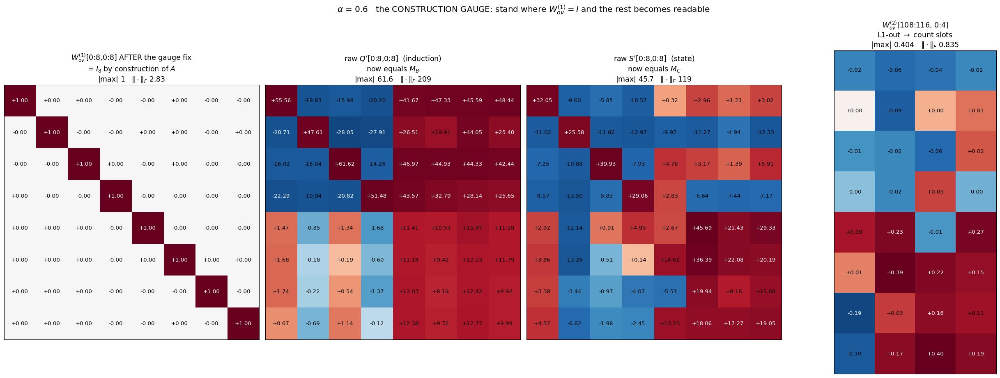

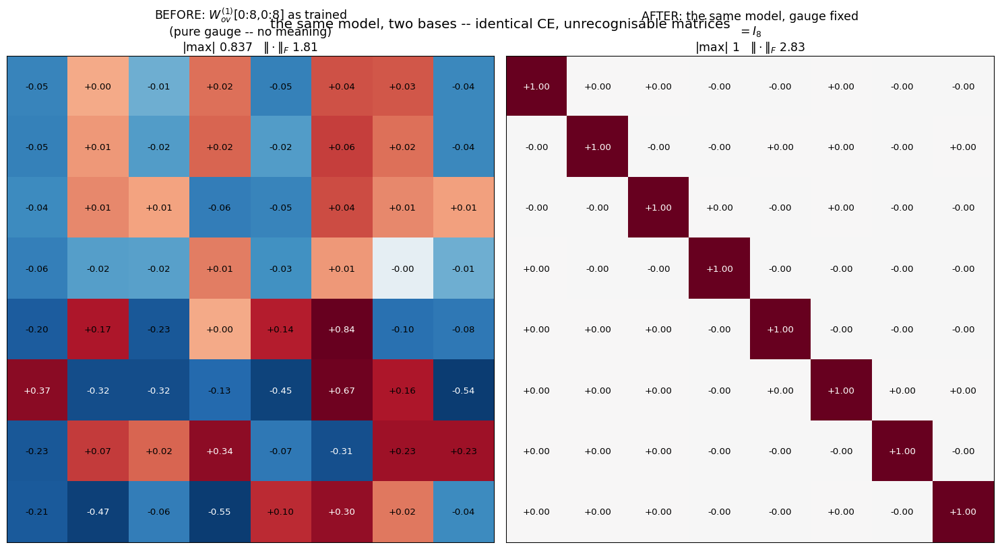

In [41]:
if _sd is not None:
    O = _sd['layer1.W_ov'][0:V, :].numpy().astype(np.float64)
    sv = np.linalg.svd(O, compute_uv=False)
    rk = int(np.linalg.matrix_rank(O, tol=1e-8))
    print('THE ONLY GAUGE-INVARIANT FACTS ABOUT W_ov1 ALONE')
    print(f'  singular values : {np.round(sv, 4)}')
    print(f'  rank            : {rk} / 8      condition number {sv[0] / sv[-1]:.2f}')
    print(f'  -> {"all 8 predecessor tokens map to independent directions; layer 2 CAN separate them"if rk == V else f"only {rk} independent directions -- {V - rk} token(s) collapsed"}')

    if rk == V:
        U_, S_, Vt_ = np.linalg.svd(O, full_matrices=True)
        Op = Vt_[:V].T @ np.diag(1.0 / S_) @ U_.T        # (108, 8)  pseudo-inverse
        Nn = Vt_[V:].T                                    # (108, 100) null space
        Ag = np.concatenate([Op, Nn], 1)
        Agi = np.linalg.inv(Ag)
        tgt = np.concatenate([np.eye(V), np.zeros((V, AD - V))], 1)
        print(f'\nconstruction gauge A = [O+ | N] : cond {np.linalg.cond(Ag):.3g}   '
              f'max|O A - [I|0]| = {np.abs(O @ Ag - tgt).max():.2e}')

        At = torch.tensor(Ag, dtype=_sd['layer1.W_ov'].dtype)
        Bm = torch.block_diag(torch.eye(D1, dtype=At.dtype), At)
        Bi = torch.linalg.inv(Bm)
        sdg = {k: v.clone() for k, v in _sd.items()}
        sdg['layer1.W_ov'] = _sd['layer1.W_ov'] @ At
        sdg['layer2.W_qk'] = Bi @ _sd['layer2.W_qk'] @ Bi.T
        sdg['layer2.W_ov'] = Bi @ _sd['layer2.W_ov']

        mdl.load_state_dict(sdg)
        print(f'CE in the construction gauge  : {eval_ce_(mdl, xb2, yb):.8f}   '
              f'(unchanged -- it is a gauge)')
        Pg, Qg, Rg, Sg = blocks(sdg)
        Mc = composites(_sd)
        print(f'raw Q\'[0:8,0:8] == composite M_B ? max|diff| = '
              f'{np.abs(Qg[0:V, 0:V].numpy() - Mc["B"]).max():.2e}')
        print(f'raw S\'[0:8,0:8] == composite M_C ? max|diff| = '
              f'{np.abs(Sg[0:V, 0:V].numpy() - Mc["C"]).max():.2e}')

        fig, ax = plt.subplots(1, 4, figsize=(FIGSCALE * 4.1, FIGSCALE * 1.5))
        heat(ax[0], sdg['layer1.W_ov'][0:V, 0:V].numpy(),
             "$W_{ov}^{(1)}$[0:8,0:8] AFTER the gauge fix\n= $I_8$ by construction of $A$",
             annot=True)
        heat(ax[1], Qg[0:V, 0:V].numpy(),
             "raw $Q'$[0:8,0:8]  (induction)\nnow equals $M_B$", annot=True)
        heat(ax[2], Sg[0:V, 0:V].numpy(),
             "raw $S'$[0:8,0:8]  (state)\nnow equals $M_C$", annot=True)
        heat(ax[3], sdg['layer2.W_ov'][D1:D1 + V, 0:Vs].numpy(),
             "$W_{ov}^{(2)}$[108:116, 0:4]\nL1-out $\\to$ count slots", annot=True)
        fig.suptitle(f'$\\alpha$ = {FZ_T}   the CONSTRUCTION GAUGE: stand where '
                     f'$W_{{ov}}^{{(1)}}=I$ and the rest becomes readable',
                     fontsize=max(13, int(2.4 * FIGSCALE)))
        plt.tight_layout(); plt.show()

        fig, ax = plt.subplots(1, 2, figsize=(FIGSCALE * 2.4, FIGSCALE * 1.3))
        heat(ax[0], _sd['layer1.W_ov'][0:V, 0:V].numpy(),
             'BEFORE: $W_{ov}^{(1)}$[0:8,0:8] as trained\n(pure gauge -- no meaning)', annot=True)
        heat(ax[1], sdg['layer1.W_ov'][0:V, 0:V].numpy(),
             'AFTER: the same model, gauge fixed\n$= I_8$', annot=True)
        fig.suptitle('the same model, two bases -- identical CE, unrecognisable matrices',
                     fontsize=max(13, int(2.4 * FIGSCALE)))
        plt.tight_layout(); plt.show()
        mdl.load_state_dict(_sd)
    else:
        print('\nrank < 8, so no A can send the token rows to I_8; the construction gauge '
              'does not exist for this checkpoint.')


## 8.7 "But the learned matrices are not aligned with the construction — so how can this work?"

A fair objection, and worth answering carefully, because if the composites were produced by
*fitting* the learned weights to the construction then every conclusion here would be circular.
They are not. Three separate points.

### (a) Nothing was aligned, removed, or subtracted

$M_B = Q[0{:}8,:]\,W_{ov}^{(1)}[0{:}8,:]^\top$ and
$M_C = W_{ov}^{(1)}[0{:}8,:]\,S\,W_{ov}^{(1)}[0{:}8,:]^\top$ are computed from the **trained
weights alone**. The construction never enters the calculation — there is no fitting, no
Procrustes, no rotation chosen to make things look good. The construction appears only
*afterwards*, as a statement to compare against.

The sandwich was not "removed". **The sandwich is the quantity.** $S$ on its own is not a
meaningful matrix; $W_{ov}^{(1)}SW_{ov}^{(1)\top}$ is.

### (b) One index is meaningful, the other is arbitrary — $W_{ov}^{(1)}$ is the dictionary between them

This is the whole idea. Layer 2's score is a bilinear form, and its two arguments carry
*different kinds* of index:

* **token indices** $0..7$ — these are real. Token 3 is token 3 in the data, in the loss, and in
  the readout. Nothing can rotate them.
* **layer-1 output indices** $0..107$ — these are internal bookkeeping. §8.3 showed any
  invertible $A$ relabels them with no observable effect whatsoever.

$h_u = W_{ov}^{(1)}[\mathrm{prev}(u),:]$ says exactly that $W_{ov}^{(1)}$ is the **dictionary**
translating a meaningful token index into the arbitrary internal one. So $Q$'s columns are
indexed arbitrarily and its entries mean nothing on their own; contracting them against
$W_{ov}^{(1)}$ **translates back into the token basis**, where the entries are answers to a
question you can actually ask.

The standard analogy: a quadratic form $q(x) = x^\top Mx$ under $x = Ay$ becomes
$M \to A^\top MA$. The *matrix* changes beyond recognition; the *form* does not. $M_C$ is that
form evaluated on the token basis — and the token basis is the one that is physically pinned.

### (c) The decisive check: $M_B$ predicts the model's behaviour, measured without it

The strongest argument is not algebraic. $M_B[v,u]$ claims to answer "if I am token $v$, how much
do I want a key whose predecessor was $u$?" That is a question about what the model *does*, and
it can be measured straight off a forward pass with no reference to $M_B$, to $W_{ov}^{(1)}$, or
to the construction — just run the model and look at where layer 2's attention lands. The cell
below does that. If the two agree, $M_B$ is a real description of the model, not a flattering
coordinate choice.


In [43]:
if _sd is not None:
    blob_ = torch.load(os.path.join('dataset', 'test', f'data_x_{FZ_T}.pt'), weights_only=False)
    xb3 = blob_['x'][:128]
    Bq, Tq = xb3.shape
    s1_ = torch.cat([F.one_hot(xb3, V).float(),
                     F.one_hot(torch.arange(Tq), 100).float().unsqueeze(0).expand(Bq, Tq, -1)], -1)
    mk = torch.triu(torch.ones(Tq, Tq) * float('-inf'), diagonal=1)
    with torch.no_grad():
        a1_ = F.softmax(torch.bmm(s1_ @ _sd['layer1.W_qk'], s1_.transpose(1, 2)) / D1 ** 0.5 + mk, -1)
        h_ = torch.bmm(a1_, s1_ @ _sd['layer1.W_ov'])
        x2_ = torch.cat([s1_, h_], -1)
        a2_ = F.softmax(torch.bmm(x2_ @ _sd['layer2.W_qk'], x2_.transpose(1, 2)) / D1 ** 0.5 + mk, -1)

    # ground truth: prev(u) = most recent SIGNAL token strictly before u
    prev = torch.full_like(xb3, -1)
    for b in range(Bq):
        last = -1
        for t in range(Tq):
            prev[b, t] = last
            if xb3[b, t] < Vs:
                last = int(xb3[b, t])

    tot = hit = 0.0
    per_v = {v: [0.0, 0.0] for v in range(Vs)}
    for b in range(Bq):
        for t in range(50, Tq):
            v = int(xb3[b, t])
            if v >= Vs:
                continue
            match = (prev[b, :t] == v)
            if match.sum() == 0:
                continue
            mass = float(a2_[b, t, :t][match].sum())
            hit += mass; tot += 1
            per_v[v][0] += mass; per_v[v][1] += 1

    print('MEASURED FROM A FORWARD PASS -- M_B, W_ov1 and the construction play no part:')
    print(f'  layer-2 attention mass on keys whose PREDECESSOR == query token : {hit/tot:.4f}')
    print(f'  uniform-attention baseline                                      : {1/Vs:.4f}')
    for v in range(Vs):
        print(f'     query token {v}: {per_v[v][0]/max(per_v[v][1],1):.4f}   '
              f'({int(per_v[v][1])} queries)')

    M = composites(_sd)
    print('\nPREDICTED FROM THE WEIGHTS -- M_B = Q[0:8,:] @ W_ov1[0:8,:].T, nothing else:')
    am = [int(np.argmax(M['B'][v, :Vs])) for v in range(Vs)]
    print(f'  argmax_u M_B[v, u] for v = 0..3 : {am}     (diagonal -> "prefer my own token")')
    print(f'  agreement with the behavioural measurement: '
          f'{"YES -- both say the induction match is diagonal" if am == list(range(Vs)) else "NO"}')
    print('\nSo the diagonality of M_B is a property the model HAS, discovered from its weights,')
    print('not a property imposed by choosing convenient coordinates.')


MEASURED FROM A FORWARD PASS -- M_B, W_ov1 and the construction play no part:
  layer-2 attention mass on keys whose PREDECESSOR == query token : 0.9297
  uniform-attention baseline                                      : 0.2500
     query token 0: 0.9252   (1017 queries)
     query token 1: 0.9305   (937 queries)
     query token 2: 0.9386   (842 queries)
     query token 3: 0.9261   (1030 queries)

PREDICTED FROM THE WEIGHTS -- M_B = Q[0:8,:] @ W_ov1[0:8,:].T, nothing else:
  argmax_u M_B[v, u] for v = 0..3 : [0, 1, 2, 3]     (diagonal -> "prefer my own token")
  agreement with the behavioural measurement: YES -- both say the induction match is diagonal

So the diagonality of M_B is a property the model HAS, discovered from its weights,
not a property imposed by choosing convenient coordinates.
